# Análise Univariada

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("../dados/processado/streaming_retencao_limpo.csv")

## Tabela de Frequência

In [ ]:
freq_absoluta = df['cancelou'].value_counts()
freq_relativa = df['cancelou'].value_counts(normalize=True)*100

In [ ]:
tabela_frequencia = pd.DataFrame({'Frequência Absoluta': freq_absoluta, 'Frequência Relativa (%)': freq_relativa})
display(tabela_frequencia)

## Gráfico de Barras

In [ ]:
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='cancelou', data=df, palette='pastel', hue='cancelou', dodge=False, stat='count', legend=False)

total = len(df['cancelou'])
for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f'{(x/total)*100:.2f}%')


plt.title('Distribuição de Cancelamentos')
plt.xlabel('Cancelou')
plt.ylabel('Contagem')
sns.despine()
plt.show()

## Conclusão

A tabela e o gráfico apontam um desbalanceamento de classes. Isso pode impactar o treinamento e avaliação do modelo. Uma avaliação usando acurácia como métrica pode ficar enviesada.

# Plotagens Básicas

In [20]:
sns.set_theme(style="whitegrid")
paleta_churn = {"Sim": "#d95f02", "Não": "#2b5c8f"}

C:\Users\muril\AppData\Local\Temp\ipykernel_18076\2287254468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


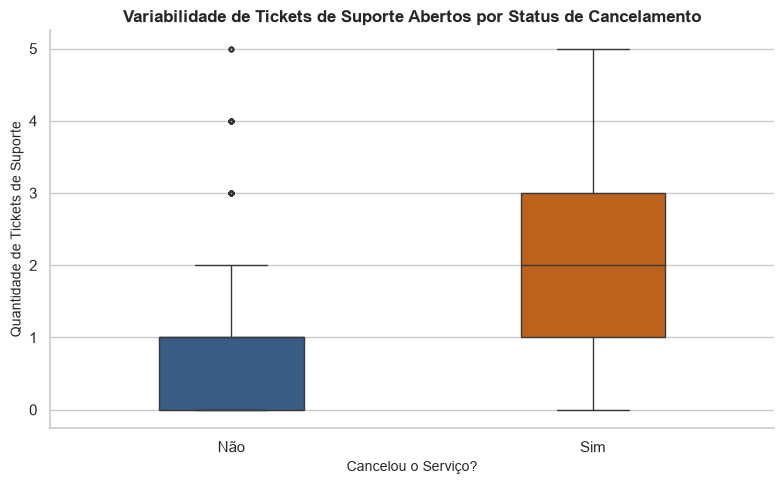

In [21]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df, 
    x='cancelou', 
    y='tickets_suporte_abertos', 
    palette=paleta_churn,
    width=0.4,
    fliersize=3
)

plt.title('Variabilidade de Tickets de Suporte Abertos por Status de Cancelamento', fontsize=12, fontweight='bold')
plt.xlabel('Cancelou o Serviço?', fontsize=10)
plt.ylabel('Quantidade de Tickets de Suporte', fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

O gráfico aponta uma relação onde quanto maior o atrito, ou seja quanto mais o cliente precisa abrir tickets por não ter sido bem auxiliado, maior o risco de churn.

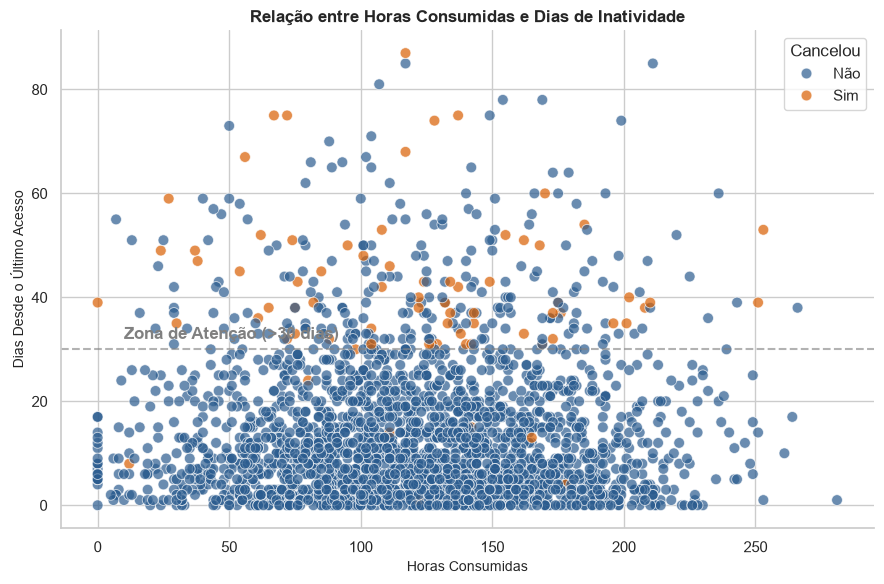

In [22]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, 
    x='horas_consumidas', 
    y='dias_desde_ultimo_acesso', 
    hue='cancelou', 
    palette=paleta_churn,
    alpha=0.7,
    s=60
)

plt.title('Relação entre Horas Consumidas e Dias de Inatividade', fontsize=12, fontweight='bold')
plt.xlabel('Horas Consumidas', fontsize=10)
plt.ylabel('Dias Desde o Último Acesso', fontsize=10)
plt.legend(title='Cancelou', frameon=True)

plt.axhline(y=30, color='gray', linestyle='--', alpha=0.6)
plt.annotate('Zona de Atenção (>30 dias)', xy=(10, 32), color='gray', fontweight='bold')

sns.despine()
plt.tight_layout()
plt.show()

O gráfico aponta que após 30 dias desde do último acesso o risco de churn é evidente. No entanto, a quantidade de horas consumidades não tem uma divisão clara. Isto significa que até clientrs engajados podem vir a cancelar o serviço após muito tempo sem uso. Deste modo, os dias desde o último acesso parece ser uma variável mais relevante do que as horas consumidas para medir o risco de churn. 

C:\Users\muril\AppData\Local\Temp\ipykernel_18076\2175048183.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


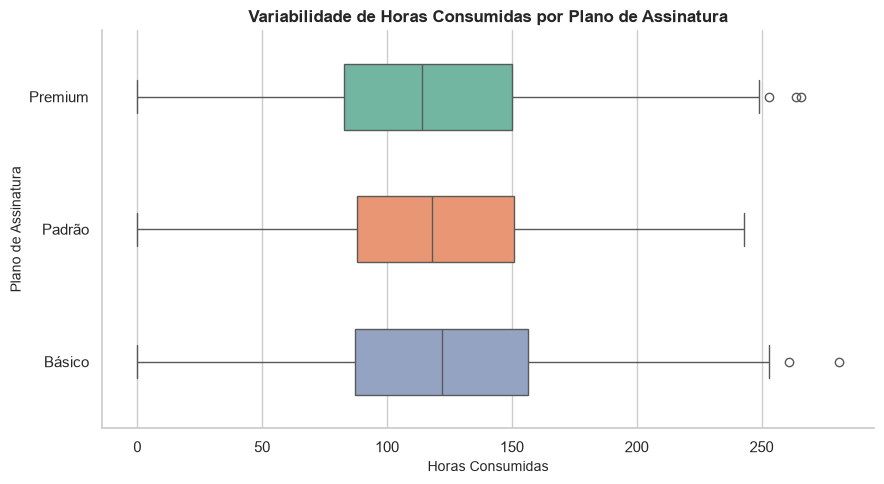

In [23]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, 
    x='horas_consumidas', 
    y='plano', 
    palette='Set2',
    orient='h',
    width=0.5
)

plt.title('Variabilidade de Horas Consumidas por Plano de Assinatura', fontsize=12, fontweight='bold')
plt.xlabel('Horas Consumidas', fontsize=10)
plt.ylabel('Plano de Assinatura', fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

O gráfico demonstra que não há uma diferença significativa no consumo de horas entre os diferentes planos de assinatura, sugerindo que o tipo de plano não influencia diretamente o comportamento de consumo dos usuários.

In [ ]:
plt.figure(figsize=(9, 5))
sns.violinplot(
    data=df, 
    x='cancelou', 
    y='series_abandonadas', 
    palette=paleta_churn,
    inner='quartile',
    cut=0
)

plt.title('Distribuição e Densidade de Séries Abandonadas por Status de Churn', fontsize=12, fontweight='bold')
plt.xlabel('Cancelou o Serviço?', fontsize=10)
plt.ylabel('Séries Abandonadas', fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

O gráfico sugere que usuários que mais começam séries e não terminam tem maior risco de churn pelo acumulo de séries que não prendem o interesse do cliente. Com isso, a insatisfação com o contéudo parece estar ligada ao risco de churn.

 # Análise Multivariada


 ## Preparação das Variáveis

In [25]:
df_correlacao = df.copy()

df_correlacao["cancelou_binario"] = df_correlacao["cancelou"].map({
    "Não": 0,
    "Sim": 1
})

df_numerico = df_correlacao.select_dtypes(include="number")

display(df_numerico.head())

,dias_desde_ultimo_acesso,idade_do_usuario,horas_consumidas,series_concluidas,series_abandonadas,tickets_suporte_abertos,cancelou_binario
0,5,27,185,7,4,0,0
1,9,18,118,5,2,1,0
2,30,31,73,4,3,0,0
3,1,25,130,3,6,0,0
4,11,24,139,4,3,0,0


 A variável `cancelou` estava em formato de texto. Por isso, foi criada a coluna `cancelou_binario`, em que 0 representa quem não cancelou e 1 representa quem cancelou. Essa mudança foi feita apenas para permitir o cálculo das correlações.

 ## Matriz de Correlação

In [24]:
matriz_correlacao = df_numerico.corr()

display(matriz_correlacao.round(2))


,dias_desde_ultimo_acesso,idade_do_usuario,horas_consumidas,series_concluidas,series_abandonadas,tickets_suporte_abertos,cancelou_binario
dias_desde_ultimo_acesso,1.00,0.01,0.01,0.02,0.00,0.03,0.33
idade_do_usuario,0.01,1.00,-0.01,0.02,-0.00,-0.01,-0.03
horas_consumidas,0.01,-0.01,1.00,-0.01,0.02,0.02,0.00
series_concluidas,0.02,0.02,-0.01,1.00,-0.02,-0.03,0.03
series_abandonadas,0.00,-0.00,0.02,-0.02,1.00,0.04,0.10
tickets_suporte_abertos,0.03,-0.01,0.02,-0.03,0.04,1.00,0.18
cancelou_binario,0.33,-0.03,0.00,0.03,0.10,0.18,1.00


 ## Heatmap das Correlações

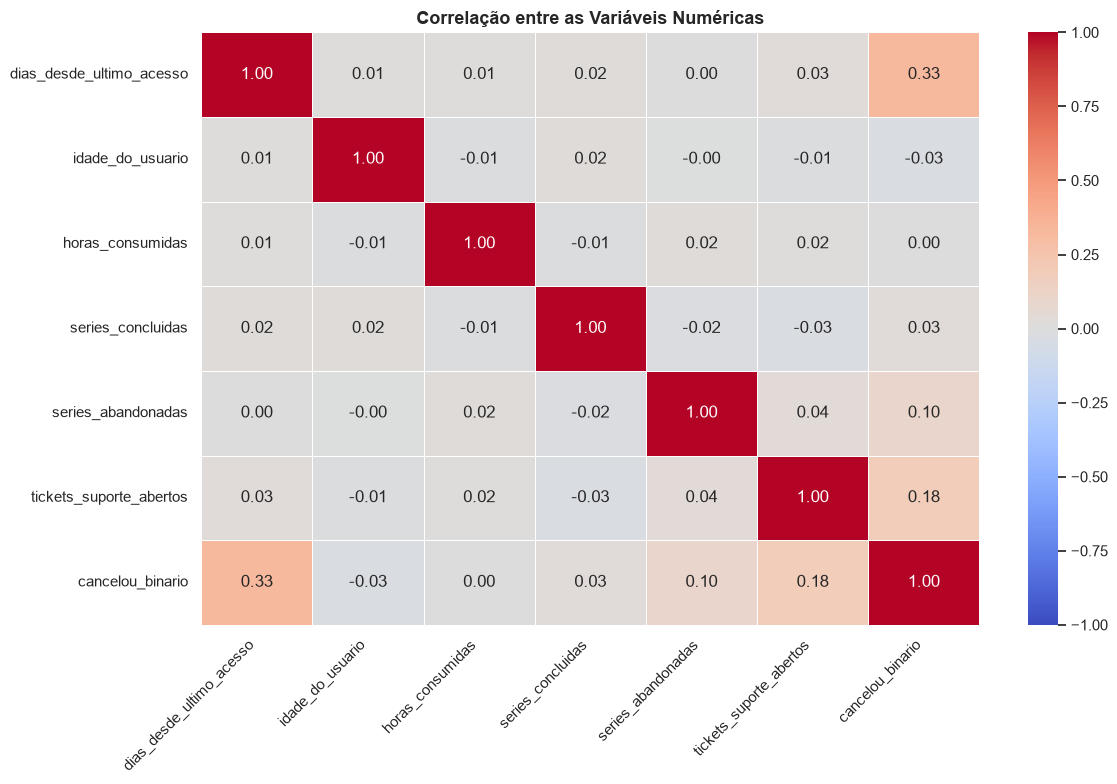

In [26]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    matriz_correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    "Correlação entre as Variáveis Numéricas",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


 ## Correlações com o Cancelamento

In [ ]:
correlacoes_churn = (
    matriz_correlacao["cancelou_binario"]
    .drop("cancelou_binario")
    .sort_values(key=lambda valores: valores.abs(), ascending=False)
)

display(
    correlacoes_churn
    .rename("Correlação com o cancelamento")
    .to_frame()
    .round(3)
)


 A tabela organiza as variáveis de acordo com a força da relação com o cancelamento.


 ## Gráfico das Correlações com o Cancelamento

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=correlacoes_churn.values,
    y=correlacoes_churn.index,
    hue=correlacoes_churn.index,
    palette="coolwarm",
    legend=False
)

plt.axvline(
    x=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Correlação das Variáveis com o Cancelamento",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Coeficiente de Correlação")
plt.ylabel("Variáveis")
plt.xlim(-1, 1)

sns.despine()
plt.tight_layout()
plt.show()


 A variável `dias_desde_ultimo_acesso` apresentou a maior correlação com o cancelamento, com valor próximo de 0,33. Isso indica que clientes que passam mais dias sem acessar a plataforma apresentam maior associação com o churn.



 Os tickets de suporte abertos tiveram correlação próxima de 0,18, enquanto as séries abandonadas tiveram correlação próxima de 0,10.



 As outras variáveis apresentaram valores muito próximos de zero, indicando pouca relação linear individual com o cancelamento.

 ## Correlação entre Variáveis de Comportamento

In [ ]:
variaveis_comportamentais = [
    "dias_desde_ultimo_acesso",
    "horas_consumidas",
    "series_concluidas",
    "series_abandonadas",
    "tickets_suporte_abertos"
]

matriz_comportamento = df_correlacao[
    variaveis_comportamentais
].corr()

display(matriz_comportamento.round(3))


 Também foi criada uma matriz apenas com as variáveis ligadas ao comportamento dos clientes. Assim, é possível verificar se ações como consumir mais horas, abandonar séries ou abrir tickets possuem relações entre si.

 ## Heatmap das Variáveis de Comportamento

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    matriz_comportamento,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title(
    "Correlação entre Variáveis de Comportamento",
    fontsize=13,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


 As correlações entre as próprias variáveis comportamentais ficaram muito próximas de zero. Isso mostra que elas representam comportamentos diferentes e não possuem relações lineares fortes entre si.



 Por exemplo, consumir mais horas não significa necessariamente abrir mais tickets ou abandonar mais séries.

 ## Maiores Correlações Encontradas

In [ ]:
mascara_superior = ns.triu(
    ns.ones(matriz_correlacao.shape, dtype=bool),
    k=1
)

pares_correlacao = (
    matriz_correlacao
    .where(mascara_superior)
    .stack()
    .rename("Correlação")
    .reset_index()
)

pares_correlacao.columns = [
    "Variável 1",
    "Variável 2",
    "Correlação"
]

pares_correlacao["Correlação Absoluta"] = (
    pares_correlacao["Correlação"].abs()
)

pares_correlacao = pares_correlacao.sort_values(
    by="Correlação Absoluta",
    ascending=False
)

display(
    pares_correlacao[
        ["Variável 1", "Variável 2", "Correlação"]
    ]
    .head(10)
    .round(3)
)


 A tabela mostra os dez pares com maiores correlações em valor absoluto. Foram retiradas as repetições e a diagonal principal, pois a matriz apresenta cada relação duas vezes e sempre mostra valor 1 na relação de uma variável com ela mesma.

 ## Conclusão



 A análise mostrou que `dias_desde_ultimo_acesso` foi a variável numérica mais relacionada ao cancelamento, com correlação próxima de 0,33. Esse resultado reforça o que já havia sido observado no gráfico de dispersão: clientes que ficam muito tempo sem acessar a plataforma apresentam maior risco de churn.



 Os tickets de suporte abertos e as séries abandonadas também apresentaram relações positivas com o cancelamento, mas com coeficientes menores.



 As horas consumidas, a idade e a quantidade de séries concluídas tiveram correlações muito próximas de zero. Além disso, as variáveis comportamentais apresentaram pouca correlação entre si.


## Interpretação técnica da Análisa Exploratória

## Análise univariada:

### Proporção de cancelamento: Sim/Não

Notou-se, numa primeira análise, que a proporção de clientes ativos para clientes que cancelaram o plano é muito baixa, sendo apenas 3.22% da amostra referente aos clientes que cancelaram, isso pode ser visto no gráfico de barras feito anteriormente e no gráfico de pizza a seguir:

In [ ]:
contagem = df['cancelou'].value_counts()
categorias = contagem.index
valores = contagem.values
cores = sns.color_palette('pastel', len(categorias))

plt.figure(figsize=(7, 7))

plt.pie (
    valores,
    labels = categorias,
    colors = cores,
    autopct = '%.2f%%',
    startangle = 90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title('Relação de Cancelamentos', fontsize=14, fontweight='bold', pad=15)
plt.axis('equal')
plt.show()

### Relação entre Tickets abertos e churn:

Como visto no BoxPlot feito anteriormente, para os dados de cancelamento realizado, a maior presença destes (d.q) situam-se numa faixa onde ticktes abertos eram entre 1 e 3, enquanto os dados que não houveram churn estão majoritariamente entre 0 e 1 tickets abertos. Isso confirma que há uma relação entre o cancelamento e a quantidade de tickets abertos, sendo uma label a ser explorada num modelo de aprendizado

### Dias de Inatividade

Ao analizar tanto o scatterplot feito anteriormente quanto o violinplot a seguir, nota-se que a densidade grande parte das pessoas que cancelaram estavam inativas de 20 a 60 dias, enquanto quem não cancelou está inativo no máximo a 40 dias num geral, vendo assim que a inatividade é uma variávl-el de grande relevância

C:\Users\muril\AppData\Local\Temp\ipykernel_18076\146910044.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


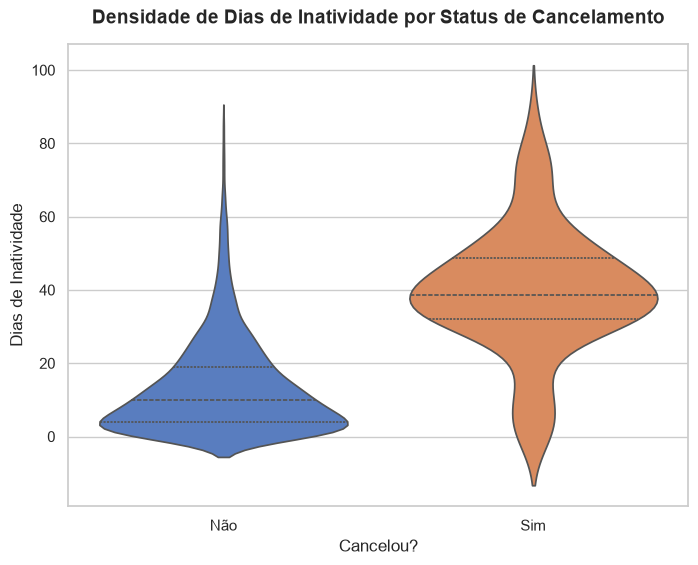

In [27]:
plt.figure(figsize=(8, 6))

sns.violinplot(
    data=df, 
    x='cancelou', 
    y='dias_desde_ultimo_acesso', 
    palette='muted',
    inner='quart'
)

plt.title('Densidade de Dias de Inatividade por Status de Cancelamento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Cancelou?', fontsize=12)
plt.ylabel('Dias de Inatividade', fontsize=12)

plt.show()

### Plano da assinatura:

A variável do plano possui pouquíssima relação com o cancelamento, como pode ser visto nos boxplots empilhados feitos anteriormente no começo do notebook. Dessa forma, essa variável poderia ser disconsiderada na etapa de machine learning para diminuir as dimensões.

## Análise Multivariada:

### Correlação entre variáveis:

Notou-se pela análise dos heatmaps feitos anteriormente que as variáveis com relação relevante com a variável alvo 'cancelou', em ordem decrescente, são:

1: Dias desde último acesso: 32.7%

2: Tickets suporte abertos: 18.5%

3: Séries abandonadas: 10.0%

4: Séries concluidas: 2.7%

Quanto à relação entre variáveis de comportamento, notou-se que não há relação relevante entre elas.

## Análise de variáveis categóricas:

### Método de pagamento:

Notou-se que a maioria dos cancelamentos vieram de assinaturas pagas por meio de cartão de crétido. Além disso poucos dados de cancelamento vieram de pagamento em PIX e Boleto. Isso sugere que há sim uma coreelação entre as variáveis, porém a maioria dos pagamentos foram feitos por cartão, logo espera-se que a maioria dos cancelamentos também seriam por cartão.

In [ ]:
df['pagamento'].value_counts()

In [ ]:
df_dispositivos = pd.crosstab(df['pagamento'], df['cancelou'])
df_dispositivos

### Dispositivo mais acessado:

Diferentemente da coluna de pagamentos, aqui vimos uma coisa interessante. A maioria dos dispositivos mais acessados são SmartTV, porém no número de cancelamentos ela possui apenas 5 a mais que Mobile, sugerindo assim que assinantes que usam maoritariamente o celular possuem maior risco de churn.

In [ ]:
df['dispositivo_mais_acesso'].value_counts()

In [ ]:
df_dispositivos = pd.crosstab(df['dispositivo_mais_acesso'], df['cancelou'])
df_dispositivos

### Gênero favorito:

Não pôde ser verificada uma relação entre a variável em questão e o cancelamento, sendo o numero de cancelamentos bem proporcional à quantidade de dados. A única irregularidade vista foi a de que pessoas que preferem filmes de Ação tendem a cancelar menos que outras, podendo sugerir que a SimonFlix é melhor para este público-alvo.

In [ ]:
df['genero_favorito'].value_counts()

In [ ]:
df_genero = pd.crosstab(df['genero_favorito'], df['cancelou'])
df_genero